# 21장 · 이상기체의 통계역학 — 예제 풀이

**열및통계물리2 · 교재 21장 이상기체의 통계역학 (Blundell & Blundell, *Concepts in Thermal Physics* 2판)**

교재 예제 21.1–21.3을 Python으로 확인한다. 위에서부터 순서대로 실행하면 된다. 단위는 SI, 그래프 라벨은 영어로 쓴다.

In [1]:
# ── 0. 준비: 라이브러리와 물리 상수 ──────────────────────────────
import numpy as np
import scipy.constants as sc
from scipy import integrate, optimize, special
import matplotlib.pyplot as plt

# 물리 상수 (SI 단위). 출처: scipy.constants = CODATA 2018 권장값
kB   = sc.k            # 볼츠만 상수 [J/K]
h    = sc.h            # 플랑크 상수 [J s]
hbar = sc.hbar         # [J s]
c    = sc.c            # 광속 [m/s]
e    = sc.e            # 기본 전하 [C]  (1 eV = e J)
NA   = sc.N_A          # 아보가드로 수 [1/mol]
R    = sc.R            # 기체 상수 [J/(mol K)]
me   = sc.m_e          # 전자 질량 [kg]
mp   = sc.m_p          # 양성자 질량 [kg]
amu  = sc.atomic_mass  # 원자 질량 단위 u [kg]
muB  = sc.physical_constants['Bohr magneton'][0]   # 보어 자기량 [J/T]
mu0  = sc.mu_0         # 진공 투자율 [N/A^2]
sigma_SB = sc.Stefan_Boltzmann                      # 스테판-볼츠만 상수 [W m^-2 K^-4]

plt.rcParams.update({'figure.figsize': (6.4, 4.0), 'axes.grid': True, 'grid.alpha': 0.3})

def compare(label, value, book, unit='', rtol=0.05):
    """계산값과 교재 답을 나란히 출력한다. rtol: 허용 상대오차 (교재 답은 보통 유효숫자 2자리)."""
    rel = abs(value - book) / abs(book)
    flag = 'OK' if rel <= rtol else 'CHECK'
    print(f'{label}: computed = {value:.4g} {unit} | textbook = {book:.4g} {unit} | rel. diff = {rel:.2%} [{flag}]')
    return rel

print('Setup complete. numpy', np.__version__)

Setup complete. numpy 2.5.3


## 예제 21.1 — 주기 경계조건으로 상태밀도 세기 (교재 303쪽)

**문제 요약.** 주기 경계조건 $\psi(L/2)=\psi(-L/2)$에서 $k_x=2\pi n_x/L$ ($n_x$는 정수)이고, 구 전체를 세어 $g(k)dk=Vk^2dk/2\pi^2$ (21.13)을 얻는다. 고정 경계조건(21.1절, $k_x=n_x\pi/L$, $n_x\ge1$)의 결과 (21.6)과 같다.

**풀이 아이디어.** 두 경계조건에서 $|\mathbf k|\le k$인 격자점 수를 직접 세어 $N(k)=Vk^3/6\pi^2$와 비교한다. $N$은 $kL$만의 함수이다.

kL =    10: fixed          7, periodic         19, formula         16.9
kL =   100: fixed      15711, periodic      16879, formula      16886.9
kL =  1000: fixed   16767882, periodic   16887219, formula   16886863.9


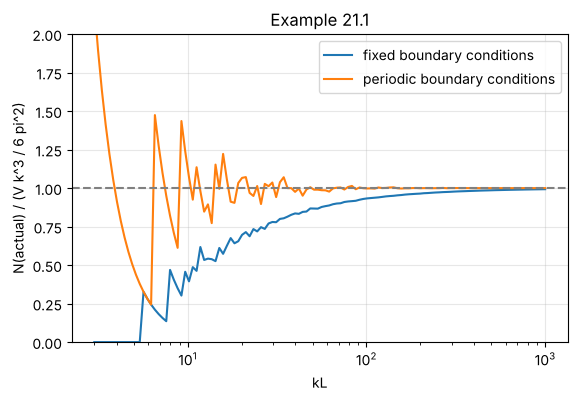

In [2]:
def count_states(kL, bc):
    """|k| <= k 인 상태 수 (V = L^3). bc = 'fixed' (n>=1) 또는 'periodic' (n 정수)"""
    s = np.pi if bc == 'fixed' else 2 * np.pi
    R = kL / s
    nmax = int(R) + 1
    n = np.arange(1, nmax + 1) if bc == 'fixed' else np.arange(-nmax, nmax + 1)
    nx, ny = np.meshgrid(n, n, indexing='ij')
    r2 = R**2 - nx**2 - ny**2                       # n_z^2 <= r2 인 n_z 개수를 해석적으로 센다
    ok = r2 >= 0
    m = np.floor(np.sqrt(np.where(ok, r2, 0)) + 1e-12)
    cnt = np.where(ok, m if bc == 'fixed' else 2 * m + 1, 0)
    return int(cnt.sum())

formula = lambda kL: kL**3 / (6 * np.pi**2)
kLs = np.logspace(np.log10(3), np.log10(1000), 120)
rf = [count_states(x, 'fixed') / formula(x) for x in kLs]
rp = [count_states(x, 'periodic') / formula(x) for x in kLs]
for x in (10, 100, 1000):
    print(f'kL = {x:5d}: fixed {count_states(x, "fixed"):>10d}, periodic {count_states(x, "periodic"):>10d}, formula {formula(x):>12.1f}')
plt.semilogx(kLs, rf, label='fixed boundary conditions')
plt.semilogx(kLs, rp, label='periodic boundary conditions')
plt.axhline(1, ls='--', c='gray'); plt.ylim(0, 2)
plt.xlabel('kL'); plt.ylabel('N(actual) / (V k^3 / 6 pi^2)'); plt.legend(); plt.title('Example 21.1'); plt.show()

**해석.** 두 경계조건 모두 $kL$이 커지면 실제 개수가 공식 $Vk^3/6\pi^2$에 수렴한다($kL=1000$에서 고정 경계 0.99, 주기 경계 1.000).
고정 경계조건은 $n_i=0$인 면을 빼므로 작은 상자에서 개수가 적다. 큰 상자에서는 경계조건과 무관하게 같은 $g(k)$를 쓸 수 있다.

## 예제 21.2 — 두 입자, 두 준위: 구별가능성 (교재 305–306쪽)

**문제 요약.** 에너지가 0 또는 $\varepsilon$인 입자 하나는 $Z_1=1+e^{-\beta\varepsilon}$ (21.20)이다. 두 입자가 구별 가능하면 상태가 4개로 $Z_2=Z_1^2$, 구별 불가능하면 3개로 $Z_2=1+e^{-\beta\varepsilon}+e^{-2\beta\varepsilon}\neq Z_1^2$ (21.24)이다.

**풀이 아이디어.** 미시상태를 직접 나열해 $Z_2$를 계산하고, 근사 $Z_1^2/2!$와 비교한다.

In [3]:
from itertools import product, combinations_with_replacement
levels = [0.0, 1.0]                                  # 에너지 (eps 단위)
dist = list(product(levels, repeat=2))               # 구별 가능: 순서쌍
indist = list(combinations_with_replacement(levels, 2))   # 구별 불가능: 순서 없는 쌍
print('distinguishable states  :', dist)
print('indistinguishable states:', indist)
print(f"{'beta*eps':>8s} {'Z1^2':>10s} {'Z2 (indist)':>12s} {'Z1^2/2!':>10s} {'ratio':>8s}")
for be in (0.1, 1.0, 3.0, 10.0):
    Z1 = sum(np.exp(-be * E) for E in levels)
    Zd = sum(np.exp(-be * sum(s)) for s in dist)
    Zi = sum(np.exp(-be * sum(s)) for s in indist)
    print(f'{be:8.1f} {Zd:10.5f} {Zi:12.5f} {Z1**2 / 2:10.5f} {Zi / (Z1**2 / 2):8.4f}')

distinguishable states  : [(0.0, 0.0), (0.0, 1.0), (1.0, 0.0), (1.0, 1.0)]
indistinguishable states: [(0.0, 0.0), (0.0, 1.0), (1.0, 1.0)]
beta*eps       Z1^2  Z2 (indist)    Z1^2/2!    ratio
     0.1    3.62841      2.72357    1.81420   1.5012
     1.0    1.87109      1.50321    0.93555   1.6068
     3.0    1.10205      1.05227    0.55103   1.9096
    10.0    1.00009      1.00005    0.50005   1.9999


**해석.** 구별 가능한 두 입자는 정확히 $Z_1^2$이다. 구별 불가능한 경우 $Z_1^2/2!$은 두 입자가 같은 상태에 있는 항까지 반으로 줄이므로 정확한 값과 다르며, 특히 저온($\beta\varepsilon$ 큼)에서 두 입자가 모두 바닥상태에 몰려 비율이 2에 가까워진다.
$1/N!$ 보정은 입자들이 거의 언제나 서로 다른 상태에 있을 때, 곧 $n\ll n_Q$ (21.27)일 때만 맞다.

## 예제 21.3 — 이상기체의 상태함수 (교재 308–309쪽)

**문제 요약.** $Z_N=\frac{1}{N!}(V/\lambda_{th}^3)^N$ (21.28)에서 $U=\tfrac32Nk_BT$, $p=nk_BT$, $H=\tfrac52Nk_BT$, $F$, 사쿠르–테트로드 $S$ (21.37), $G=Nk_BT\ln(n\lambda_{th}^3)$ (21.38)을 유도한다.

**풀이 아이디어.** $\ln Z_N$을 함수로 두고 수치미분으로 $U=-\partial\ln Z/\partial\beta$, $p=k_BT\,\partial\ln Z/\partial V$, $S=k_B(\ln Z+\beta U)$를 구해 해석식과 비교한다.
**가정(입력값):** 헬륨 기체 1 mol, $T=300$ K, $V=24.6$ L (약 1 atm). $\ln N!$은 정확한 $\ln\Gamma(N+1)$로 계산한다.

In [4]:
m = 4.002602 * amu                 # He 원자 질량 [kg] (원자량 4.0026)
N = NA                             # 1 mol
T0, V0 = 300.0, 24.6e-3            # [K], [m^3]

def lam_th(T): return h / np.sqrt(2 * np.pi * m * kB * T)            # (21.18)
def lnZ(beta, V):                                                      # (21.28)
    T = 1 / (kB * beta)
    return N * np.log(V / lam_th(T)**3) - special.gammaln(N + 1)

b0 = 1 / (kB * T0)
db, dV = b0 * 1e-6, V0 * 1e-6
U = -(lnZ(b0 + db, V0) - lnZ(b0 - db, V0)) / (2 * db)
p = (lnZ(b0, V0 + dV) - lnZ(b0, V0 - dV)) / (2 * dV) / b0
S = kB * (lnZ(b0, V0) + b0 * U)
n = N / V0
S_ST = N * kB * (2.5 - np.log(n * lam_th(T0)**3))                     # (21.37)
F = -kB * T0 * lnZ(b0, V0)
G = F + p * V0
print(f'lambda_th = {lam_th(T0):.4e} m,  n lambda^3 = {n * lam_th(T0)**3:.3e}  (<< 1: classical)')
print(f'U = {U:.4f} J      (3/2 N k_B T = {1.5 * N * kB * T0:.4f} J)')
print(f'p = {p:.2f} Pa   (n k_B T = {n * kB * T0:.2f} Pa)')
print(f'H = U + pV = {U + p * V0:.4f} J  (5/2 N k_B T = {2.5 * N * kB * T0:.4f} J)')
print(f'S = {S:.4f} J/K   (Sackur-Tetrode = {S_ST:.4f} J/K, per mole: {S_ST:.2f} J mol^-1 K^-1)')
print(f'G = F + pV = {G:.2f} J  (N k_B T ln(n lambda^3) = {N * kB * T0 * np.log(n * lam_th(T0)**3):.2f} J)')

lambda_th = 5.0381e-11 m,  n lambda^3 = 3.131e-06  (<< 1: classical)
U = 3741.5082 J      (3/2 N k_B T = 3741.5082 J)
p = 101395.88 Pa   (n k_B T = 101395.89 Pa)
H = U + pV = 6235.8469 J  (5/2 N k_B T = 6235.8470 J)
S = 126.1662 J/K   (Sackur-Tetrode = 126.1662 J/K, per mole: 126.17 J mol^-1 K^-1)
G = F + pV = -31614.01 J  (N k_B T ln(n lambda^3) = -31614.01 J)


**해석.** $\ln Z_N$을 수치미분한 값이 교재의 해석식 $U=\tfrac32Nk_BT$, $p=nk_BT$, $H=\tfrac52Nk_BT$, $G=Nk_BT\ln(n\lambda_{th}^3)$과 일치한다.
엔트로피도 사쿠르–테트로드 식과 표시된 자릿수까지 같다(정확한 $\ln N!$과 스털링 근사의 차이는 $N=N_A$에서 무시할 만하다). $n\lambda_{th}^3\sim10^{-6}$이므로 고전 이상기체 근사가 잘 맞는다.